# 01 · Data preparation: sources, class mapping, leak-free splits, sanity checks, statistics

**Project:** Traffic Density and Congestion Estimation from Single Images

Steps (each one calls a script in `scripts/`, so it can also be run from the command line):

1. **Download** a reproducible random subset of the public **UVH-26** dataset (IISc, CC BY 4.0;
   Bengaluru traffic-camera frames). Skipped if already downloaded.
2. **Map classes** from UVH-26's 14 classes to our 5 classes and write YOLO labels.
3. **Group frames by camera.** Camera ids were removed from UVH-26, so frames are grouped into
   *pseudo-cameras* by perceptual-hash and CNN-layout similarity; thresholds calibrated visually below.
4. **Split by group** (train / val / test, seed 42), then run the **automated leakage check**.
5. **Sanity checks** on every label file, **dataset statistics and plots**, sample images.
6. Status of the **external Wikimedia Commons photos** (congestion-level test only).

## 1. Setup

In [1]:
# ------------------------------------------------------------------------------------------
# Environment setup. The same cell works locally (VS Code, .venv kernel) and in Google Colab.
# ------------------------------------------------------------------------------------------
import os, sys, random, subprocess, time, json, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Mount Google Drive and locate the project folder (the one that contains trafficlib.py).
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_FOLDER_NAME = "TrafficProject"   # <- change if your Drive folder has another name
    my_drive = Path("/content/drive/MyDrive")
    candidates = [my_drive / DRIVE_FOLDER_NAME, *my_drive.glob(f"*/{DRIVE_FOLDER_NAME}"),
                  *my_drive.glob(f"*/*/{DRIVE_FOLDER_NAME}")]
    PROJECT_DIR = next((p for p in candidates if (p / "trafficlib.py").exists()), None)
    assert PROJECT_DIR is not None, (
        f"Could not find {DRIVE_FOLDER_NAME}/trafficlib.py in My Drive. If the folder was shared with "
        "you, right-click it > Organize > Add shortcut to My Drive, or edit DRIVE_FOLDER_NAME.")
    # Colab already ships torch, torchvision, transformers, OpenCV, pandas, matplotlib, scikit-learn.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.218", "imagehash"],
                   check=True)
else:
    # Local run: paths are relative to the notebook's own folder (no absolute paths).
    here = Path.cwd()
    PROJECT_DIR = here if (here / "trafficlib.py").exists() else here.parent
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))
print("project folder:", PROJECT_DIR.name, "| running in Colab:", IN_COLAB)

project folder: TrafficProject | running in Colab: False


In [2]:
# Core libraries + fixed seeds (42) so every run gives the same numbers.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

from IPython.display import display, Markdown
from trafficlib import (CLASS_NAMES, UVH26_TO_PROJECT, CLASS_HEX, INK_2, MUTED, apply_plot_style, list_images,
                        load_image_rgb, read_yolo_labels, label_path_for, load_ground_truth, draw_detections)
apply_plot_style()

torch 2.14.1+cu126 | device: CPU


## 2. Configuration

In [3]:
N_UVH        = 3200     # UVH-26 images to sample (seed 42)
GROUP_DIST   = 12       # pHash distance that links two frames into one pseudo-camera
SCENE_SIM    = 0.62     # ... or CNN layout similarity that links them (calibrated in section 5)
LEAK_SIM     = 0.70     # CNN similarity flagged as "same scene" by the leakage check
LEAK_DIST    = 8        # pHash distance treated as a near-duplicate by the leakage check
UVH_DIR      = Path("data/_raw/uvh26")
DATA         = Path("data")
OWN          = DATA / "own_photos"
OUT          = Path("outputs") / "data_prep"
OUT.mkdir(parents=True, exist_ok=True)
PY = sys.executable

def run(args):
    """Run a project script and show its output."""
    r = subprocess.run([PY, *args], capture_output=True, text=True)
    print(r.stdout[-6000:])
    if r.returncode != 0:
        print(r.stderr[-3000:])
    return r.returncode

## 3. Download the UVH-26 subset
`scripts/download_uvh26.py` pools the labelled images of UVH-26 (STAPLE consensus labels, the
more reliable of the two label sets), samples `N_UVH` of them with seed 42, and stores them as JPEGs.

In [4]:
have = len(list((UVH_DIR / "images").glob("*.jpg"))) if (UVH_DIR / "images").exists() else 0
if have < N_UVH or not (UVH_DIR / "uvh26_subset.json").exists():
    run(["scripts/download_uvh26.py", "--n", str(N_UVH)])     # ~1 image/s on a home connection
else:
    print(f"already downloaded: {have} images in {UVH_DIR.as_posix()}/images")
subset = json.loads((UVH_DIR / "uvh26_subset.json").read_text())
print(subset["info"]["description"], "|", len(subset["images"]), "images,", len(subset["annotations"]), "boxes")

already downloaded: 3200 images in data/_raw/uvh26/images


UVH-26 random subset (n=3200, seed=42, labels=ST) | 3200 images, 41891 boxes


## 4. Class mapping (UVH-26 → project classes) and conversion to YOLO format

In [5]:
cat_name = {c["id"]: c["name"] for c in subset["categories"]}
src_counts = pd.Series([cat_name[a["category_id"]] for a in subset["annotations"]]).value_counts()
mapping = pd.DataFrame({"UVH-26 class": list(UVH26_TO_PROJECT),
                        "project class": [v or "(dropped)" for v in UVH26_TO_PROJECT.values()]})
mapping = mapping[mapping["UVH-26 class"].isin(src_counts.index)]
mapping["boxes in subset"] = mapping["UVH-26 class"].map(src_counts).astype(int)
display(mapping.set_index("UVH-26 class"))
_ = run(["scripts/convert_to_yolo.py", "--source", "uvh26", "--format", "coco",
     "--coco", str(UVH_DIR / "uvh26_subset.json"), "--out-labels", str(UVH_DIR / "labels")])

,project class,boxes in subset
UVH-26 class,,
Hatchback,car,3721
Sedan,car,2471
SUV,car,2006
MUV,car,1322
Van,car,292
Two-wheeler,two_wheeler,18777
Bicycle,two_wheeler,656
Three-wheeler,auto_rickshaw,6439
Bus,bus,1192


converted 3200 label files -> data\_raw\uvh26\labels
source class counts : {'Two-wheeler': 18777, 'Three-wheeler': 6439, 'Hatchback': 3721, 'Sedan': 2471, 'LCV': 2413, 'Truck': 2249, 'SUV': 2006, 'MUV': 1322, 'Bus': 1192, 'Bicycle': 656, 'Van': 292, 'Tempo-traveller': 183, 'Mini-bus': 136, 'Others': 34}
project class counts: {'car': 9812, 'two_wheeler': 19433, 'auto_rickshaw': 6439, 'bus': 1511, 'truck': 4662}
dropped (unmapped classes): 34 boxes | dropped (degenerate < 2 px): 0 boxes



## 5. Pseudo-cameras: calibrating how frames are grouped by camera
UVH-26 has no camera ids, so we must recognise frames of the same fixed camera ourselves. Two
signals are combined:

* **pHash** (64-bit perceptual hash): very close for near-identical frames, but street scenes share
  coarse structure, so it misses same-camera frames once traffic or light changes.
* **CNN layout descriptor**: ImageNet ResNet18 features on a 4×7 grid of the frame (keeps *where* the
  buildings, poles and road are), compared by cosine similarity.

Two frames are linked if pHash ≤ `GROUP_DIST` **or** CNN similarity ≥ `SCENE_SIM`; connected
components are the pseudo-cameras. Linking is transitive, so too loose a threshold chains unrelated
cameras into one giant group. The thresholds below were chosen by looking at pairs (figures in this
section) and at the group-size table.

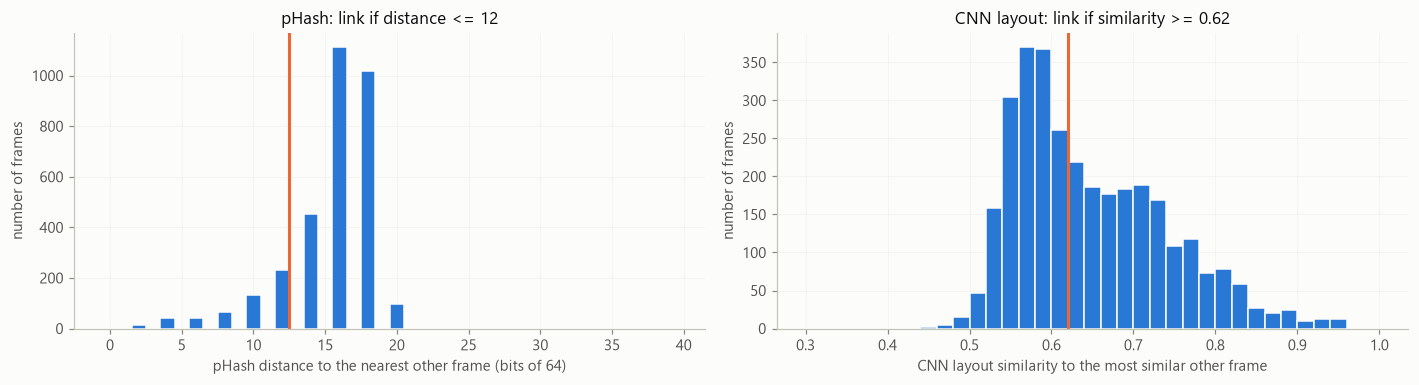

,groups,largest group (frames),largest group (%),singletons
CNN threshold,,,,
0.58,1158,1532,47.9,887
0.60,1651,691,21.6,1239
0.62,1956,192,6.0,1488
0.65,2206,60,1.9,1778
0.70,2489,46,1.4,2152


3200 frames -> 1956 pseudo-cameras (expected about 1987 distinct cameras if frames were spread evenly) | largest group 192 | singletons 1488


In [6]:
sys.path.insert(0, str(PROJECT_DIR / "scripts"))
from check_leakage import phash_int, hamming_matrix, scene_features
from make_splits import pseudo_camera_groups
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

uvh_imgs = sorted((UVH_DIR / "images").glob("*.jpg"))
gids = pseudo_camera_groups(uvh_imgs, GROUP_DIST, cache=UVH_DIR / "phash_cache.csv",
                            scene_sim=SCENE_SIM, feat_cache=DATA / "_cache" / "scene_features.npz")
cache = dict(line.split(",") for line in (UVH_DIR / "phash_cache.csv").read_text().splitlines())
H = np.array([int(cache[p.name]) for p in uvh_imgs], dtype=np.uint64)
Fs = scene_features(uvh_imgs, DATA / "_cache" / "scene_features.npz")
D = hamming_matrix(H, H); np.fill_diagonal(D, 64)
S = Fs @ Fs.T; np.fill_diagonal(S, -1)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(D.min(1), bins=np.arange(-0.5, 40.5, 1), color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
ax[0].axvline(GROUP_DIST + 0.5, color="#eb6834", lw=2)
ax[0].set(xlabel="pHash distance to the nearest other frame (bits of 64)", ylabel="number of frames",
          title=f"pHash: link if distance <= {GROUP_DIST}")
ax[1].hist(S.max(1), bins=np.arange(0.30, 1.001, 0.02), color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
ax[1].axvline(SCENE_SIM, color="#eb6834", lw=2)
ax[1].set(xlabel="CNN layout similarity to the most similar other frame", ylabel="number of frames",
          title=f"CNN layout: link if similarity >= {SCENE_SIM}")
plt.tight_layout(); plt.savefig(OUT / "pseudo_camera_calibration.png", bbox_inches="tight"); plt.show()

# group sizes for candidate thresholds (pHash <= GROUP_DIST in every row)
rows = []
for cs in [0.58, 0.60, 0.62, 0.65, 0.70]:
    n, lab = connected_components(csr_matrix((D <= GROUP_DIST) | (S >= cs)), directed=False)
    sz = np.bincount(lab)
    rows.append({"CNN threshold": cs, "groups": n, "largest group (frames)": int(sz.max()),
                 "largest group (%)": round(100 * sz.max() / len(uvh_imgs), 1), "singletons": int((sz == 1).sum())})
display(pd.DataFrame(rows).set_index("CNN threshold"))

# sanity check: expected number of distinct cameras if frames were spread evenly over ~2,800 cameras
pool, cams = 21726, 2800
expected = cams * (1 - (1 - len(uvh_imgs) / pool) ** (pool / cams))
sizes = pd.Series(gids).value_counts()
print(f"{len(uvh_imgs)} frames -> {len(sizes)} pseudo-cameras (expected about {expected:.0f} distinct cameras if "
      f"frames were spread evenly) | largest group {int(sizes.max())} | singletons {int((sizes == 1).sum())}")

**Visual check of the thresholds.** Most similar other frame for frames in different similarity bands
(pairs not already linked by pHash). Down to about 0.6 the pairs show the same camera view (same
shops, poles, flyover pillars, even day vs night); below about 0.58 they are different places.

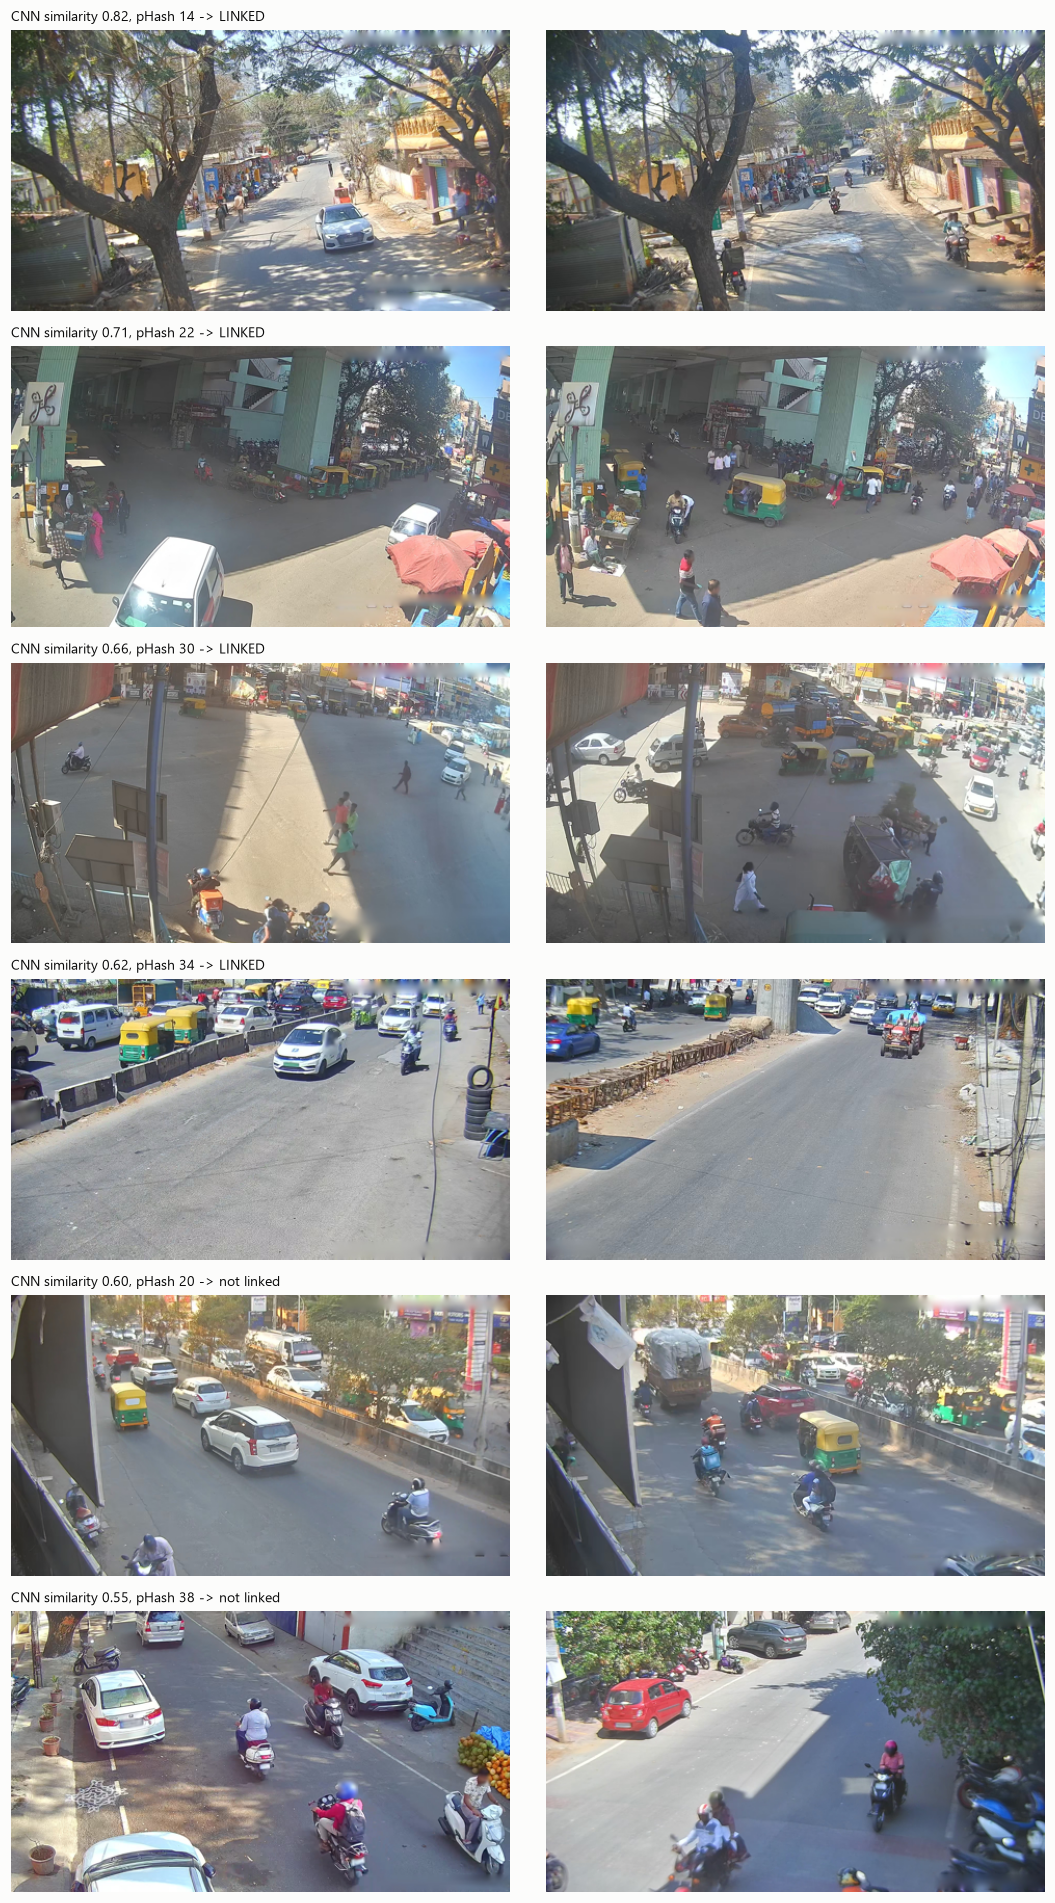

In [7]:
from PIL import Image as PILImage
nn_j = S.argmax(1); nn_s = S.max(1)
bands = [(0.80, 0.90), (0.70, 0.75), (0.64, 0.68), (0.62, 0.64), (0.58, 0.61), (0.52, 0.56)]
fig, axes = plt.subplots(len(bands), 2, figsize=(10, 2.9 * len(bands)))
for r, (lo, hi) in enumerate(bands):
    cand = [i for i in np.where((nn_s >= lo) & (nn_s < hi))[0] if D[i, nn_j[i]] > GROUP_DIST]
    for c in range(2):
        axes[r, c].axis("off")
    if not cand:
        continue
    i = cand[len(cand) // 2]
    for c, k in enumerate([i, nn_j[i]]):
        axes[r, c].imshow(PILImage.open(uvh_imgs[k]).resize((480, 270)))
    linked = "LINKED" if nn_s[i] >= SCENE_SIM else "not linked"
    axes[r, 0].set_title(f"CNN similarity {nn_s[i]:.2f}, pHash {D[i, nn_j[i]]} -> {linked}", fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(OUT / "pseudo_camera_pairs.png", bbox_inches="tight", dpi=80); plt.show()

## 6. Leak-free train / val / test split + leakage check
`scripts/make_splits.py` assigns whole pseudo-cameras to train / val / test-pool (70 / 15 / 15 %,
seed 42); 300 frames of held-out pseudo-cameras form the box-annotated test set (box-annotated
photos from other sources, grouped by location, would also go to test). It then runs the leakage check: exact duplicates (MD5),
near-duplicates (pHash ≤ 8 across splits), same-scene pairs (CNN similarity ≥ 0.70 across splits)
and groups appearing in two splits.

In [8]:
rc = run(["scripts/make_splits.py", "--group-dist", str(GROUP_DIST), "--scene-sim", str(SCENE_SIM),
          "--leak-dist", str(LEAK_DIST), "--leak-scene-sim", str(LEAK_SIM)])
print("leakage check:", "PASS" if rc == 0 else "FAIL (see data/leakage_report.csv)")
manifest = pd.read_csv(DATA / "splits_manifest.csv")
display(manifest.groupby(["split", "source"]).agg(images=("file", "count"), groups=("group", "nunique"),
                                                   boxes=("n_boxes", "sum")))

﻿UVH-26 images with labels: 3200
  scene features 32/479
pseudo-camera groups: 1956 (largest 192 images, 1488 singletons)
extra photos: 0 with box labels, 118 without (not in the box-level splits)
test set: 300 held-out UVH-26 images

images per split and source:
  train: uvh26=2241, own=0 | boxes: {'truck': 3310, 'car': 6883, 'auto_rickshaw': 4622, 'two_wheeler': 13763, 'bus': 1076}
  val  : uvh26=480, own=0 | boxes: {'auto_rickshaw': 841, 'truck': 636, 'car': 1432, 'bus': 191, 'two_wheeler': 2759}
  test : uvh26=300, own=0 | boxes: {'two_wheeler': 1841, 'auto_rickshaw': 637, 'truck': 456, 'car': 923, 'bus': 170}
  unused UVH-26 test-pool images: 179

running leakage check ...
images per split: {'train': 2241, 'val': 480, 'test': 300}
leakage summary: {'exact_duplicates': 0, 'near_duplicates': 0, 'same_scene_pairs': 0, 'groups_crossing_splits': 0, 'phash_max_dist': 8, 'scene_sim_threshold': 0.7, 'n_images': {'train': 2241, 'val': 480, 'test': 300}, 'clean': True}
PASS: no leakage foun

,,images,groups,boxes
split,source,,,
test,uvh26,300,218,4027
train,uvh26,2241,1316,29654
unused,uvh26,179,144,2317
val,uvh26,480,317,5859


## 7. Sanity checks on every label file

In [9]:
problems = []
for split in ["train", "val", "test"]:
    for p in list_images(DATA / split / "images"):
        lab = label_path_for(p)
        if not lab.exists():
            problems.append((split, p.name, "missing label file")); continue
        for k, line in enumerate(lab.read_text().splitlines()):
            v = line.split()
            if len(v) != 5:
                problems.append((split, p.name, f"line {k + 1}: {len(v)} values")); continue
            c, xc, yc, w, h = int(v[0]), *map(float, v[1:])
            if not 0 <= c < len(CLASS_NAMES): problems.append((split, p.name, f"line {k + 1}: class {c}"))
            if not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < w <= 1 and 0 < h <= 1):
                problems.append((split, p.name, f"line {k + 1}: coordinates out of range"))
    orphans = {q.stem for q in (DATA / split / "labels").glob("*.txt")} - {p.stem for p in list_images(DATA / split / "images")}
    problems += [(split, o, "label without image") for o in orphans]
print(f"label problems found: {len(problems)}")
display(pd.DataFrame(problems, columns=["split", "file", "problem"]).head(20))

label problems found: 0


,split,file,problem


## 8. Dataset statistics

class,images,boxes,car,two_wheeler,auto_rickshaw,bus,truck,vehicles / image
split,,,,,,,,
train,2241,29654,6883,13763,4622,1076,3310,13.2
val,480,5859,1432,2759,841,191,636,12.2
test,300,4027,923,1841,637,170,456,13.4


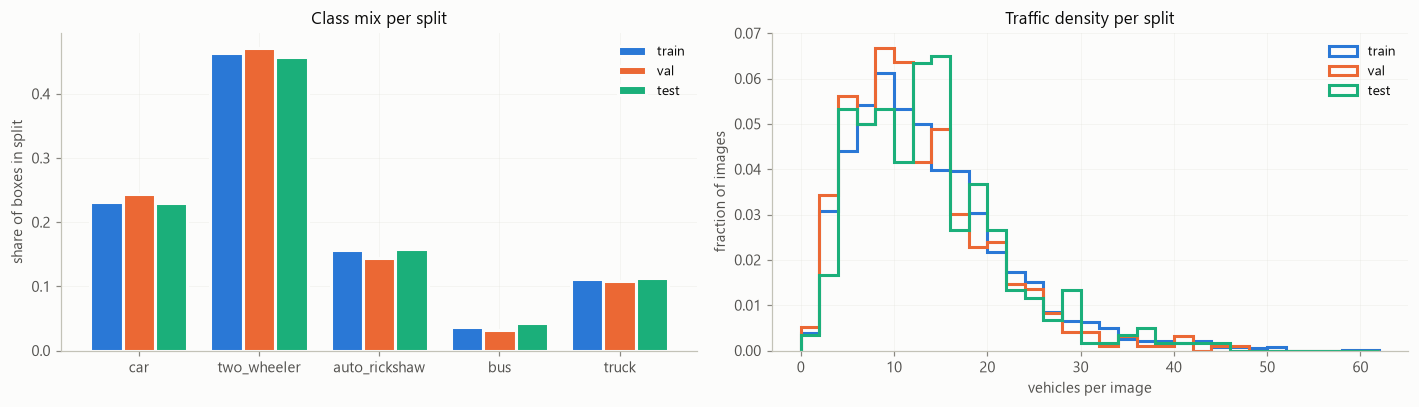

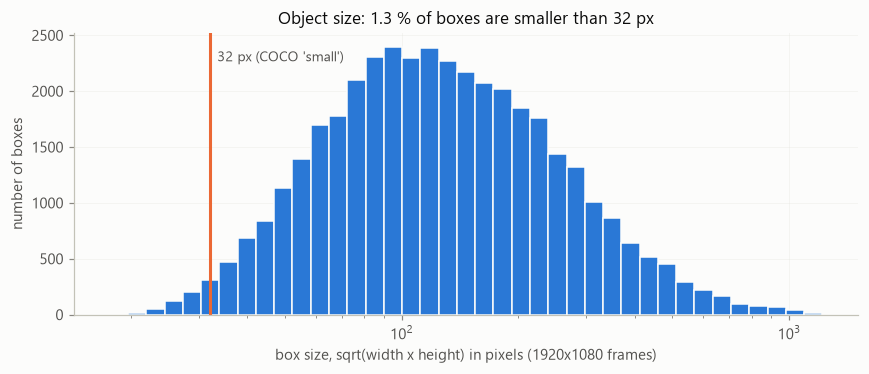

class,auto_rickshaw,bus,car,truck,two_wheeler
median box area (% of image),0.648,1.781,1.08,2.086,0.467


In [10]:
recs = []
for split in ["train", "val", "test"]:
    for p in list_images(DATA / split / "images"):
        b, c, (h, w) = load_ground_truth(p)
        for (x1, y1, x2, y2), cc in zip(b, c):
            recs.append({"split": split, "image": p.name, "class": CLASS_NAMES[cc], "w_px": x2 - x1, "h_px": y2 - y1,
                         "area_frac": (x2 - x1) * (y2 - y1) / (w * h)})
boxes = pd.DataFrame(recs)
imgs = {s: len(list_images(DATA / s / "images")) for s in ["train", "val", "test"]}
stats = boxes.pivot_table(index="split", columns="class", values="image", aggfunc="count", fill_value=0)
stats = stats.reindex(index=["train", "val", "test"], columns=CLASS_NAMES, fill_value=0)
stats.insert(0, "boxes", stats.sum(axis=1)); stats.insert(0, "images", pd.Series(imgs))
stats["vehicles / image"] = (stats["boxes"] / stats["images"]).round(1)
display(stats)
per_img = boxes.groupby(["split", "image"]).size()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
share = stats[CLASS_NAMES].div(stats["boxes"], axis=0)
x = np.arange(len(CLASS_NAMES)); w = 0.27
for k, (split, col) in enumerate(zip(["train", "val", "test"], ["#2a78d6", "#eb6834", "#1baf7a"])):
    ax.bar(x + (k - 1) * w, share.loc[split].values, w, color=col, edgecolor="#fcfcfb", linewidth=2, label=split)
ax.set_xticks(x, CLASS_NAMES); ax.set(ylabel="share of boxes in split", title="Class mix per split")
ax.legend()
ax = axes[1]
bins = np.arange(0, per_img.max() + 3, 2)
for split, col in zip(["train", "val", "test"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.hist(per_img[split].values, bins=bins, density=True, histtype="step", lw=2, color=col, label=split)
ax.set(xlabel="vehicles per image", ylabel="fraction of images", title="Traffic density per split")
ax.legend()
plt.tight_layout(); plt.savefig(OUT / "class_mix_and_density.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
side = np.sqrt(boxes["w_px"] * boxes["h_px"])
ax.hist(side, bins=np.logspace(np.log10(max(side.min(), 4)), np.log10(side.max()), 40), color="#2a78d6",
        edgecolor="#fcfcfb", linewidth=1)
ax.set_xscale("log"); ax.axvline(32, color="#eb6834", lw=2)
ax.annotate("32 px (COCO 'small')", (32, ax.get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points", fontsize=9, color=INK_2)
ax.set(xlabel="box size, sqrt(width x height) in pixels (1920x1080 frames)", ylabel="number of boxes",
       title=f"Object size: {100 * (side < 32).mean():.1f} % of boxes are smaller than 32 px")
plt.tight_layout(); plt.savefig(OUT / "box_sizes.png", bbox_inches="tight"); plt.show()
display(boxes.groupby("class")["area_frac"].median().mul(100).round(3).rename("median box area (% of image)").to_frame().T)

## 9. Sample images with ground-truth boxes

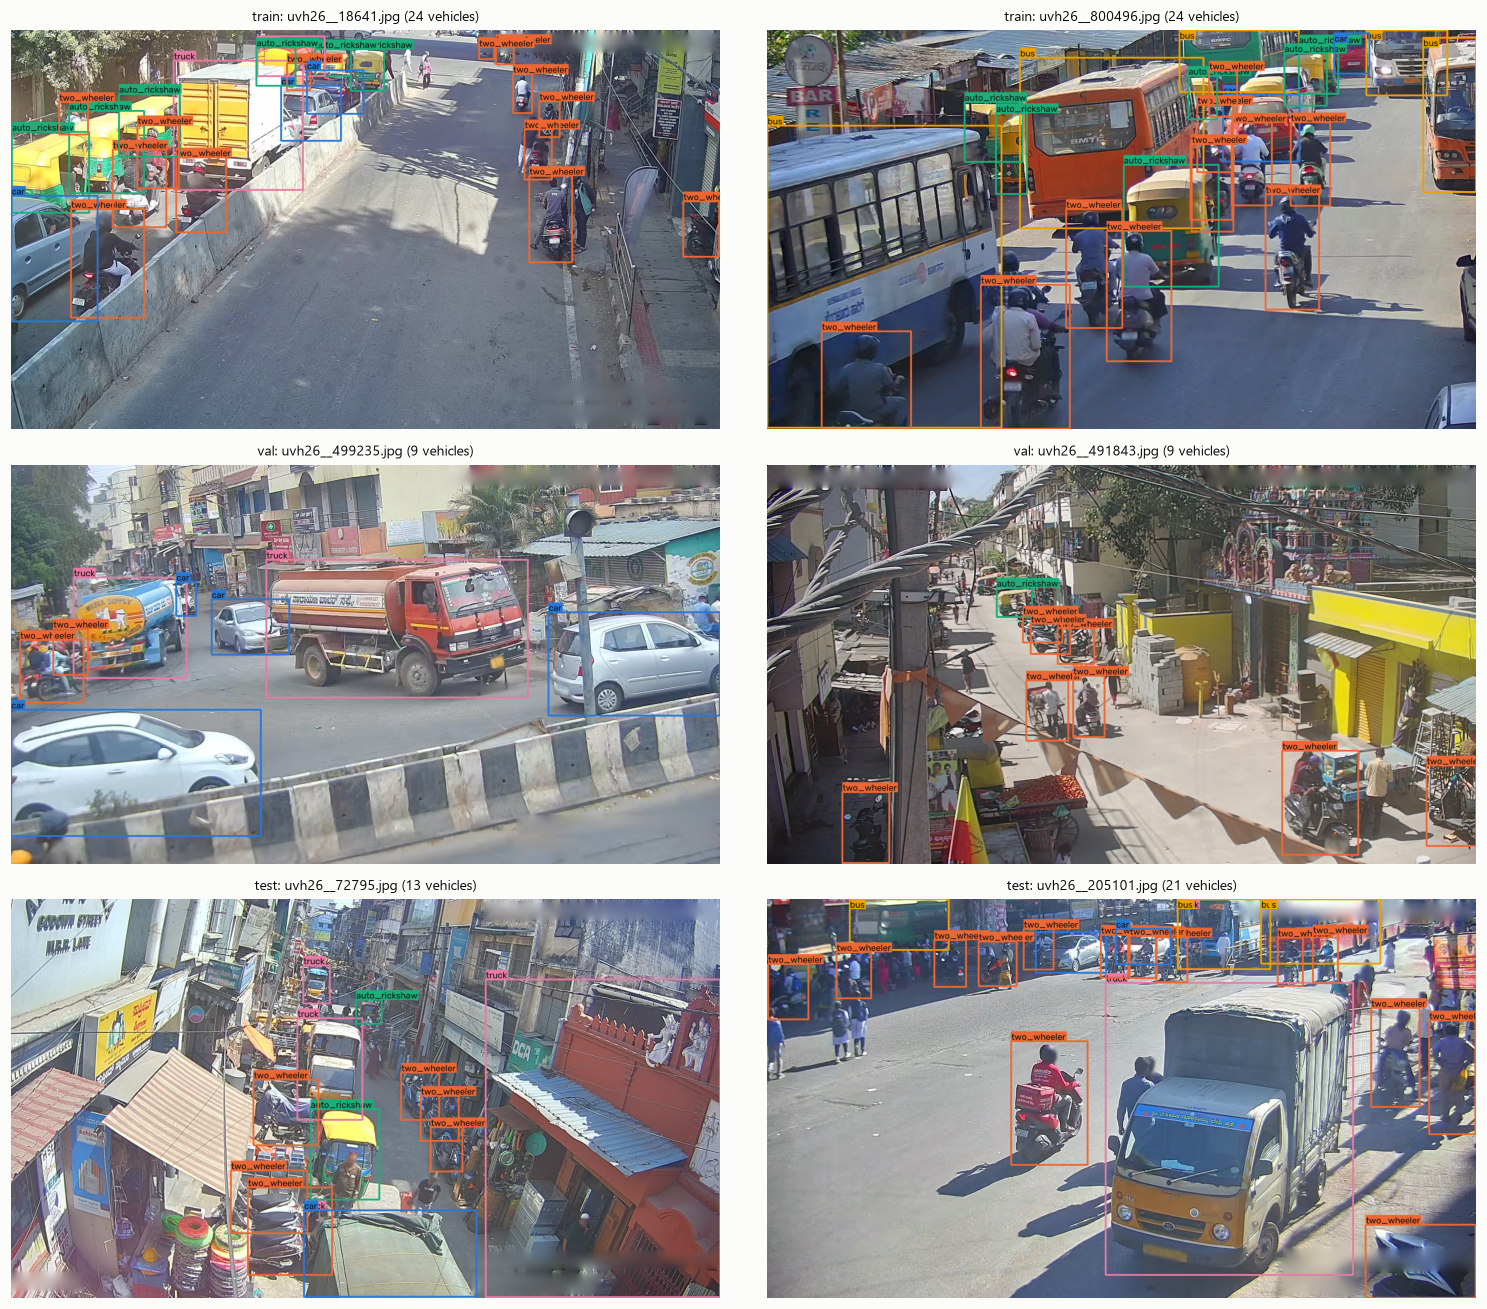

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
rng = np.random.default_rng(SEED)
for r, split in enumerate(["train", "val", "test"]):
    paths = list_images(DATA / split / "images")
    for c, i in enumerate(rng.choice(len(paths), size=min(2, len(paths)), replace=False)):
        b, cl, _ = load_ground_truth(paths[i])
        axes[r, c].imshow(draw_detections(load_image_rgb(paths[i]), b, cl)); axes[r, c].axis("off")
        axes[r, c].set_title(f"{split}: {paths[i].name} ({len(b)} vehicles)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "samples.png", bbox_inches="tight", dpi=90); plt.show()

## 10. External photos (Wikimedia Commons)
Indian road photos from Wikimedia Commons, used as an external test of the congestion level in
`traffic_flow_main.ipynb` (section 12). Collected with `scripts/collect_commons.py` from the categories
*Traffic congestion in India* and ordinary street/road categories, screened by eye, checked for overlap
with train + val, and labelled free / moderate / heavy (`data/own_photos/congestion_labels.csv`).
Author, licence and link of every file: `data/own_photos/commons_sources.csv`. These photos have no
boxes and are not used for training, validation or the box-level test set.

In [ ]:
src_file, lab_file = OWN / "commons_sources.csv", OWN / "congestion_labels.csv"
commons = pd.read_csv(src_file) if src_file.exists() else pd.DataFrame(columns=["file", "place", "licence"])
levels = pd.read_csv(lab_file).set_index("image")["level"] if lab_file.exists() else pd.Series(dtype=str)
commons["level"] = commons["file"].map(levels)
status = (commons.groupby("place").agg(photos=("file", "size"), labelled=("level", "count"))
          .join(commons.pivot_table(index="place", columns="level", values="file", aggfunc="size", fill_value=0)))
display(status)
print("licences:", commons["licence"].value_counts().to_dict())
n_commons, n_commons_labelled = len(commons), int(commons["level"].notna().sum())
print(f"external photos: {n_commons}, with a congestion label: {n_commons_labelled}")

,photos,labelled,free,heavy,moderate
place,,,,,
bengaluru,23,23,12,8,3
delhi,19,19,11,4,4
himachal_pradesh,7,7,0,7,0
india,11,11,5,3,3
kolkata,27,27,0,20,7
maharashtra,10,10,1,9,0
mumbai,8,8,4,0,4
new_delhi,2,2,0,1,1
telangana,6,6,0,6,0


licences: {'CC BY-SA 4.0': 33, 'CC BY 3.0': 29, 'CC BY-SA 3.0': 25, 'CC BY-SA 2.0': 16, 'CC BY 2.0': 7, 'CC0': 3, 'CC BY 3.0 pl': 3, 'Public domain': 1, 'CC BY 4.0': 1}
external photos: 118, with a congestion label: 118


In [12]:
json.dump({"uvh26_images": len(uvh_imgs), "pseudo_cameras": int(len(sizes)), "group_dist": GROUP_DIST,
           "scene_sim": SCENE_SIM, "expected_cameras": round(float(expected)),
           "split_images": imgs, "split_boxes": {s: int(stats.loc[s, "boxes"]) for s in imgs},
           "class_counts": {s: {c: int(stats.loc[s, c]) for c in CLASS_NAMES} for s in imgs},
           "commons_photos": n_commons, "commons_level_labels": n_commons_labelled, "label_problems": len(problems),
           "leakage_check_pass": rc == 0, "small_box_fraction": float((side < 32).mean())},
          open(OUT / "data_stats.json", "w"), indent=2)
print("saved", (OUT / "data_stats.json").as_posix())

saved outputs/data_prep/data_stats.json
